In [1]:
from __future__ import annotations

from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
import seaborn as sns
import anndata as ad
import scanpy as sc

# ------------------------------------------------------------------------
# Load 
# ------------------------------------------------------------------------
scores = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv", index_col='SNP')
scores = scores.drop('macro_mean', axis=1)
meta = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv")


# ------------------------------------------------------------------------
# Transpose and clean metadata
# ------------------------------------------------------------------------
scores_T = scores.T

adata = ad.AnnData(scores_T)

meta = meta.drop_duplicates()
meta_resolved = meta.sort_values(['SNP', 'dist']).drop_duplicates('SNP', keep='first')

adata.var = pd.merge(adata.var, meta_resolved, on='SNP')
adata.var_names = adata.var['SNP'].values
adata.var_names_make_unique()
adata.obs['cell_type'] = adata.obs.index.astype('category')




/div/pythagoras/u4/eirikhoy/.local/share/uv/python/cpython-3.12.11-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


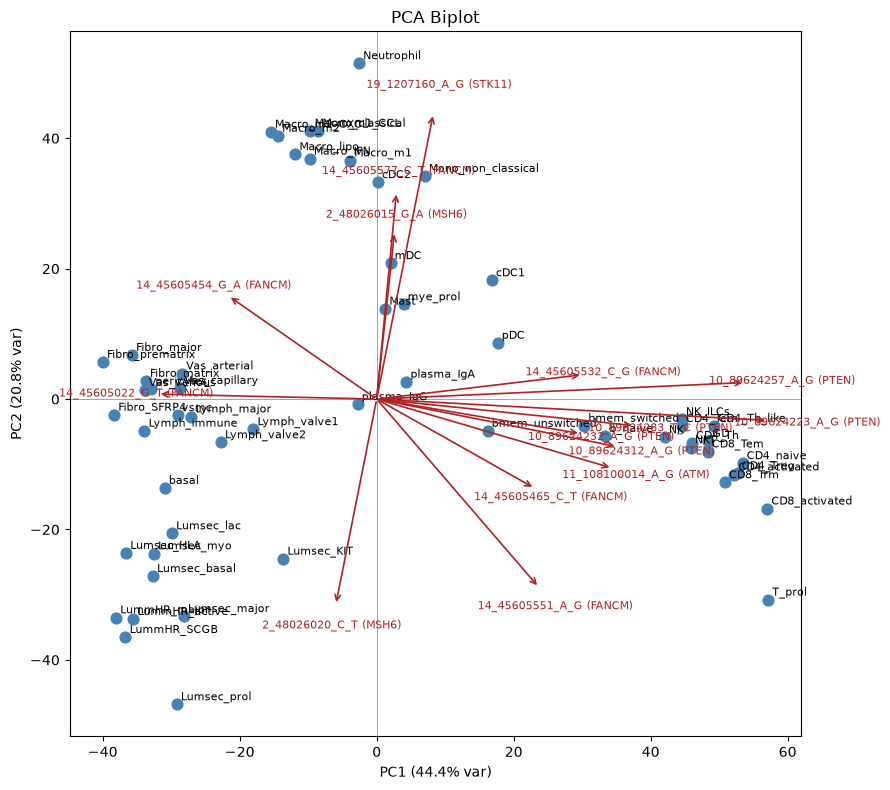

In [2]:
# ------------------------------------------------------------------------
# Run PCA
# ------------------------------------------------------------------------
# sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=10, svd_solver='arpack')


# scores: adata.obsm['X_pca']      -> (n_cell_types, n_comps)
# loadings: adata.varm['PCs']      -> (n_SNPs, n_comps)
# variance explained: adata.uns['pca']['variance_ratio']


# ------------------------------------------------------------------------
# Build the biplot
# ------------------------------------------------------------------------
def pca_biplot(adata, pc_x=0, pc_y=1, n_top_loadings=15, scale_arrows=1.0,
                label_points=True, figsize=(9, 8)):
    scores = adata.obsm['X_pca'][:, [pc_x, pc_y]]
    loadings = adata.varm['PCs'][:, [pc_x, pc_y]]
    var_ratio = adata.uns['pca']['variance_ratio']

    fig, ax = plt.subplots(figsize=figsize)

    # --- scores (cell types) ---
    ax.scatter(scores[:, 0], scores[:, 1], color='steelblue', s=60, zorder=3)
    if label_points:
        for i, label in enumerate(adata.obs_names):
            ax.annotate(label, (scores[i, 0], scores[i, 1]),
                        fontsize=8, xytext=(3, 3), textcoords='offset points')

    # --- loadings (SNPs) — only plot the top contributors, or it's unreadable ---
    loading_norm = np.sqrt((loadings ** 2).sum(axis=1))
    top_idx = np.argsort(loading_norm)[-n_top_loadings:]

    # scale arrows to be visible relative to score spread
    arrow_scale = scale_arrows * np.abs(scores).max() / np.abs(loadings[top_idx]).max()

    for i in top_idx:
        x, y = loadings[i, 0] * arrow_scale, loadings[i, 1] * arrow_scale
        ax.annotate('', xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color='firebrick', lw=1.2))

        snp_id = adata.var_names[i]
        gene = adata.var['gene_name'].iloc[i]
        label = f'{snp_id} ({gene})'
        
        ax.text(x * 1.1, y * 1.1, label,
                color='firebrick', fontsize=8, ha='center', va='center')

    ax.axhline(0, color='grey', lw=0.5)
    ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlabel(f'PC{pc_x+1} ({var_ratio[pc_x]*100:.1f}% var)')
    ax.set_ylabel(f'PC{pc_y+1} ({var_ratio[pc_y]*100:.1f}% var)')
    ax.set_title('PCA Biplot')
    fig.tight_layout()
    return fig, ax

fig, ax = pca_biplot(adata, pc_x=0, pc_y=1, n_top_loadings=15)
plt.show()

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

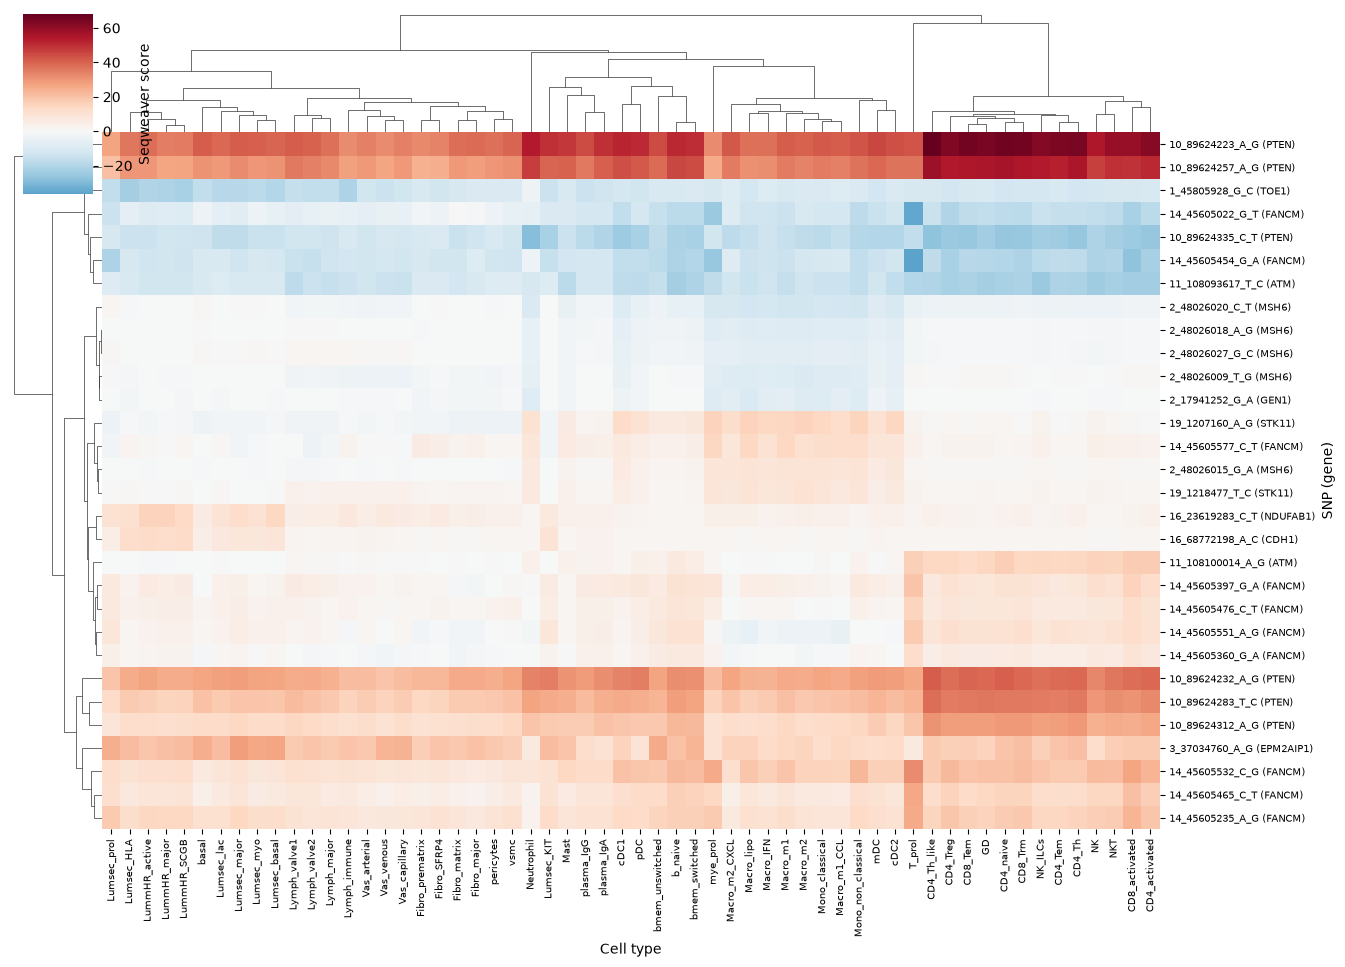

In [3]:
loadings = adata.varm['PCs'][:, [0, 1]] # get loadings for PC1 and PC2
loading_norm = np.sqrt((loadings ** 2).sum(axis=1))

n_top = 30
top_idx = np.argsort(loading_norm)[-n_top:][::-1] # descending, strong first

top_snp_ids = adata.var_names[top_idx]
top_gene_names = adata.var['gene_name'].iloc[top_idx].values

row_labels = [f'{s} ({g})' for s, g in zip(top_snp_ids, top_gene_names)]


mat = adata.X[:, top_idx].T
mat_df = pd.DataFrame(mat, index=row_labels, columns=adata.obs_names)

# ------------------------------------------------------------------------
# Plot — clustermap so similar SNPs / similar cell types group together
# ------------------------------------------------------------------------
g = sns.clustermap(
    mat_df,
    cmap='RdBu_r',
    center=0,                      # meaningful if scores are signed (delta-style scores)
    figsize=(14, 10),
    xticklabels=True,
    yticklabels=True,
    cbar_kws={'label': 'Seqweaver score'},
    dendrogram_ratio=(0.08, 0.15),
)
g.ax_heatmap.set_xlabel('Cell type')
g.ax_heatmap.set_ylabel('SNP (gene)')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, fontsize=7)
plt.setp(g.ax_heatmap.get_yticklabels(), fontsize=7)

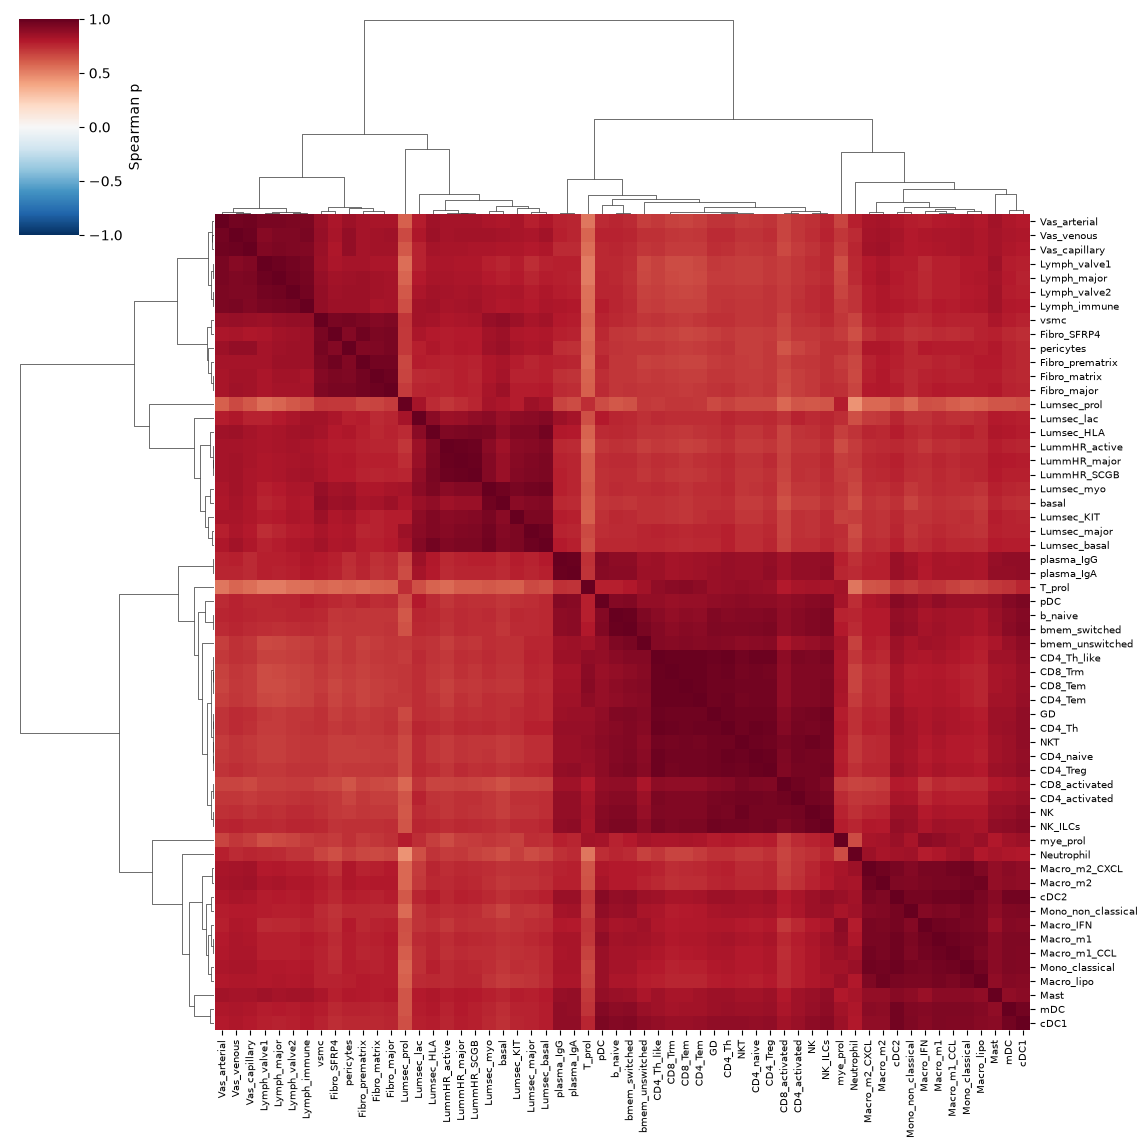

In [14]:
X = adata.X.T

z = pd.DataFrame(X, index=adata.var_names, columns=adata.obs_names)

corr = z.corr(method='spearman')

g = sns.clustermap(

    corr,
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    method='average', metric='correlation',
    figsize=(12, 12),
    xticklabels=True, yticklabels=True,
    cbar_kws={'label': 'Spearman p'},
)

plt.setp(g.ax_heatmap.get_xticklabels(), fontsize=7)
plt.setp(g.ax_heatmap.get_yticklabels(), fontsize=7)

adata.uns['cell_type_corr'] = corr

In [ ]:
adata

In [ ]:
# ------------------------------------------------------------------------
# Build the biplot
# ------------------------------------------------------------------------
def pca_biplot(adata, pc_x=0, pc_y=1, n_top_loadings=15, scale_arrows=1.0,
                label_points=True, figsize=(9, 8)):
    scores = adata.obsm['X_pca'][:, [pc_x, pc_y]]
    loadings = adata.varm['PCs'][:, [pc_x, pc_y]]
    var_ratio = adata.uns['pca']['variance_ratio']

    fig, ax = plt.subplots(figsize=figsize)

    # --- scores (cell types) ---
    ax.scatter(scores[:, 0], scores[:, 1], color='steelblue', s=60, zorder=3)
    if label_points:
        for i, label in enumerate(adata.obs_names):
            ax.annotate(label, (scores[i, 0], scores[i, 1]),
                        fontsize=8, xytext=(3, 3), textcoords='offset points')

    # --- loadings (SNPs) — only plot the top contributors, or it's unreadable ---
    loading_norm = np.sqrt((loadings ** 2).sum(axis=1))
    top_idx = np.argsort(loading_norm)[-n_top_loadings:]

    # scale arrows to be visible relative to score spread
    arrow_scale = scale_arrows * np.abs(scores).max() / np.abs(loadings[top_idx]).max()

    for i in top_idx:
        x, y = loadings[i, 0] * arrow_scale, loadings[i, 1] * arrow_scale
        ax.annotate('', xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color='firebrick', lw=1.2))

        snp_id = adata.var_names[i]
        gene = adata.var['gene_name'].iloc[i]
        label = f'{snp_id} ({gene})'
        
        ax.text(x * 1.1, y * 1.1, label,
                color='firebrick', fontsize=8, ha='center', va='center')

    ax.axhline(0, color='grey', lw=0.5)
    ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlabel(f'PC{pc_x+1} ({var_ratio[pc_x]*100:.1f}% var)')
    ax.set_ylabel(f'PC{pc_y+1} ({var_ratio[pc_y]*100:.1f}% var)')
    ax.set_title('PCA Biplot')
    fig.tight_layout()
    return fig, ax


In [ ]:
GENE_OF_INTEREST = 'BRCA1'

plot_df = adata[:,adata.var.gene_name == GENE_OF_INTEREST].copy()

# ------------------------------------------------------------------------
# Run PCA
# ------------------------------------------------------------------------
# sc.pp.scale(adata)
sc.tl.pca(plot_df, n_comps=10, svd_solver='arpack')


# scores: adata.obsm['X_pca']      -> (n_cell_types, n_comps)
# loadings: adata.varm['PCs']      -> (n_SNPs, n_comps)
# variance explained: adata.uns['pca']['variance_ratio']

fig, ax = pca_biplot(plot_df, pc_x=0, pc_y=1, n_top_loadings=15)
plt.show()

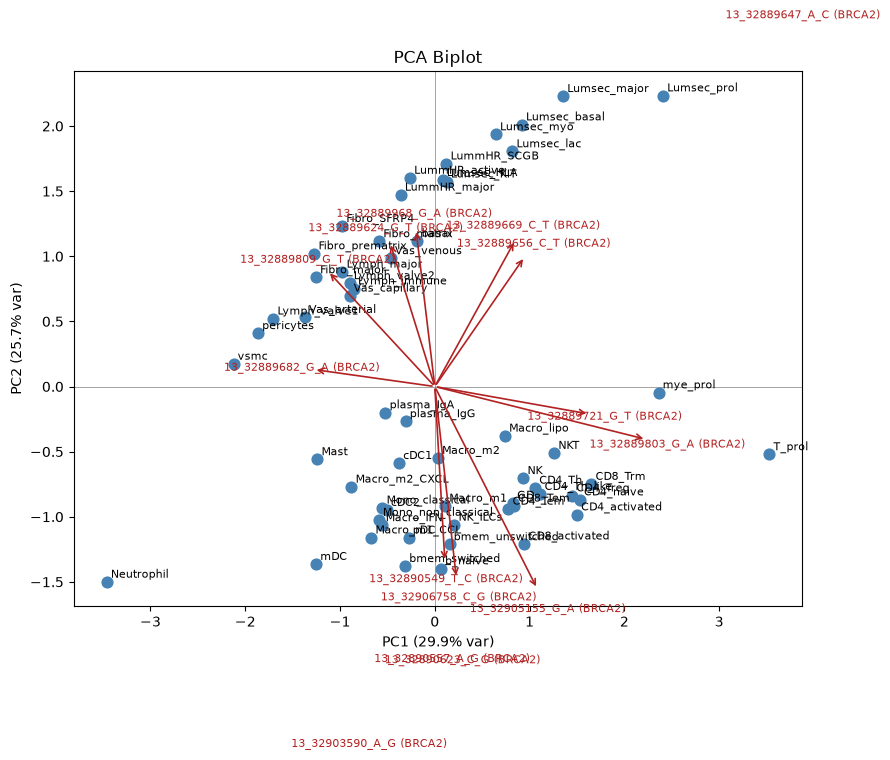

In [16]:

brca2 = adata[:,adata.var.gene_name == 'BRCA2'].copy()



# ------------------------------------------------------------------------
# Run PCA
# ------------------------------------------------------------------------
# sc.pp.scale(adata)
sc.tl.pca(brca2, n_comps=10, svd_solver='arpack')


# scores: adata.obsm['X_pca']      -> (n_cell_types, n_comps)
# loadings: adata.varm['PCs']      -> (n_SNPs, n_comps)
# variance explained: adata.uns['pca']['variance_ratio']


# ------------------------------------------------------------------------
# Build the biplot
# ------------------------------------------------------------------------
def pca_biplot(brca2, pc_x=0, pc_y=1, n_top_loadings=15, scale_arrows=1.0,
                label_points=True, figsize=(9, 8)):
    scores = brca2.obsm['X_pca'][:, [pc_x, pc_y]]
    loadings = brca2.varm['PCs'][:, [pc_x, pc_y]]
    var_ratio = brca2.uns['pca']['variance_ratio']

    fig, ax = plt.subplots(figsize=figsize)

    # --- scores (cell types) ---
    ax.scatter(scores[:, 0], scores[:, 1], color='steelblue', s=60, zorder=3)
    if label_points:
        for i, label in enumerate(brca2.obs_names):
            ax.annotate(label, (scores[i, 0], scores[i, 1]),
                        fontsize=8, xytext=(3, 3), textcoords='offset points')

    # --- loadings (SNPs) — only plot the top contributors, or it's unreadable ---
    loading_norm = np.sqrt((loadings ** 2).sum(axis=1))
    top_idx = np.argsort(loading_norm)[-n_top_loadings:]

    # scale arrows to be visible relative to score spread
    arrow_scale = scale_arrows * np.abs(scores).max() / np.abs(loadings[top_idx]).max()

    for i in top_idx:
        x, y = loadings[i, 0] * arrow_scale, loadings[i, 1] * arrow_scale
        ax.annotate('', xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color='firebrick', lw=1.2))

        snp_id = brca2.var_names[i]
        gene = brca2.var['gene_name'].iloc[i]
        label = f'{snp_id} ({gene})'
        
        ax.text(x * 1.1, y * 1.1, label,
                color='firebrick', fontsize=8, ha='center', va='center')

    ax.axhline(0, color='grey', lw=0.5)
    ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlabel(f'PC{pc_x+1} ({var_ratio[pc_x]*100:.1f}% var)')
    ax.set_ylabel(f'PC{pc_y+1} ({var_ratio[pc_y]*100:.1f}% var)')
    ax.set_title('PCA Biplot')
    fig.tight_layout()
    return fig, ax

fig, ax = pca_biplot(brca2, pc_x=0, pc_y=1, n_top_loadings=15)
plt.show()

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

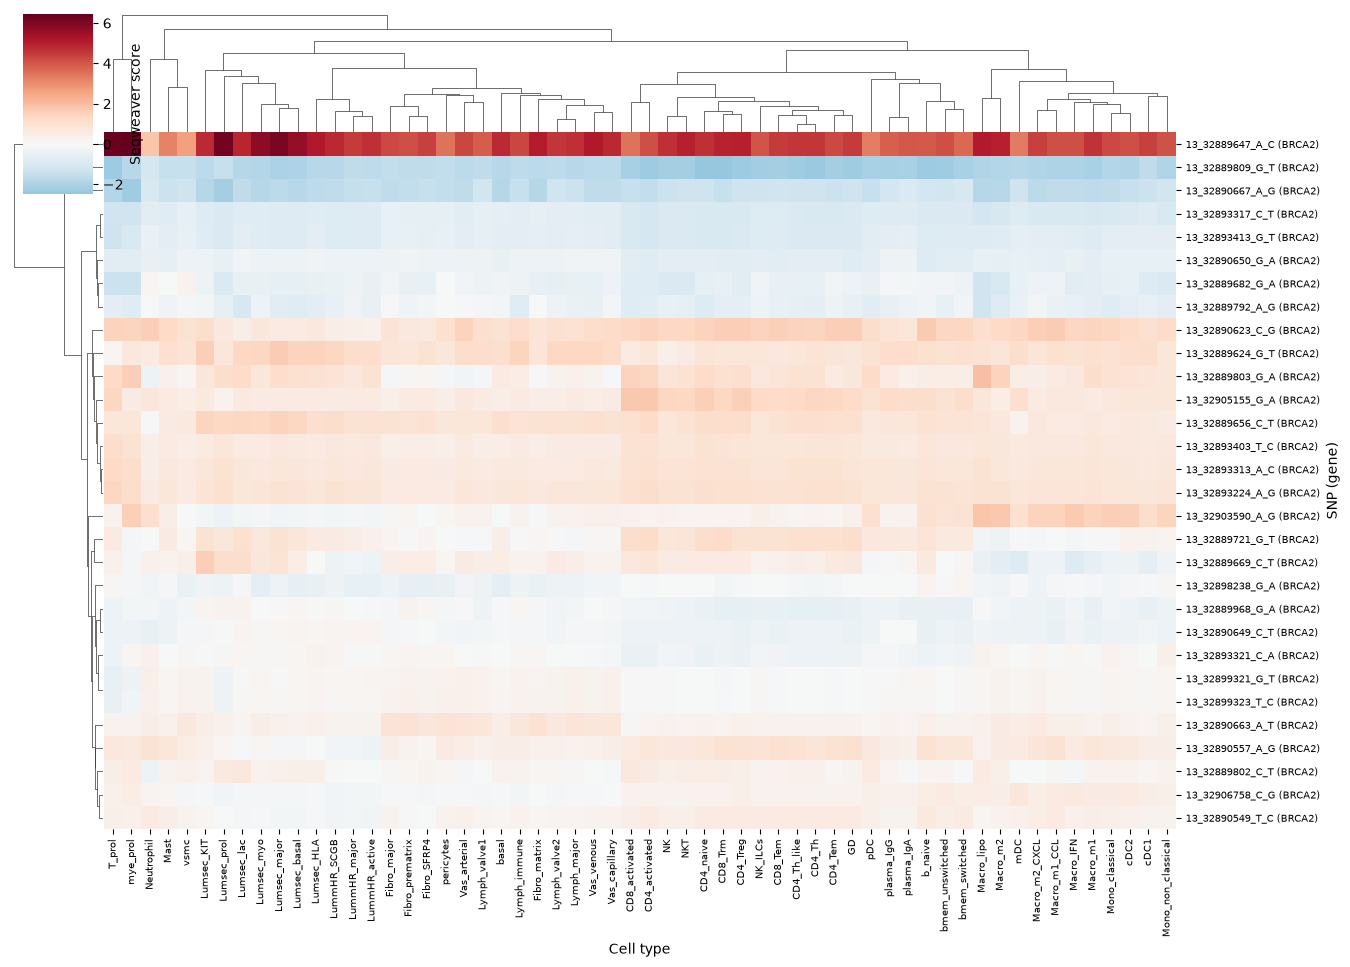

In [ ]:
loadings = brca2.varm['PCs'][:, [0, 1]] # get loadings for PC1 and PC2
loading_norm = np.sqrt((loadings ** 2).sum(axis=1))

n_top = 30
top_idx = np.argsort(loading_norm)[-n_top:][::-1] # descending, strong first

top_snp_ids = brca2.var_names[top_idx]
top_gene_names = brca2.var['gene_name'].iloc[top_idx].values

row_labels = [f'{s} ({g})' for s, g in zip(top_snp_ids, top_gene_names)]


mat = brca2.X[:, top_idx].T
mat_df = pd.DataFrame(mat, index=row_labels, columns=brca2.obs_names)

# ------------------------------------------------------------------------
# Plot — clustermap so similar SNPs / similar cell types group together
# ------------------------------------------------------------------------
g = sns.clustermap(
    mat_df,
    cmap='RdBu_r',
    center=0,                      # meaningful if scores are signed (delta-style scores)
    figsize=(14, 10),
    xticklabels=True,
    yticklabels=True,
    cbar_kws={'label': 'Seqweaver score'},
    dendrogram_ratio=(0.08, 0.15),
)
g.ax_heatmap.set_xlabel('Cell type')
g.ax_heatmap.set_ylabel('SNP (gene)')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, fontsize=7)
plt.setp(g.ax_heatmap.get_yticklabels(), fontsize=7)

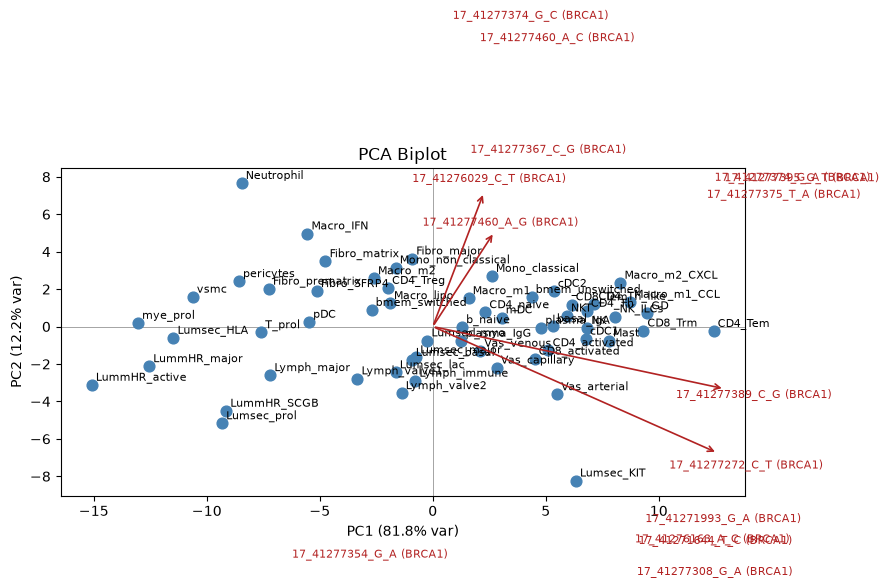

In [9]:

GENE_OF_INTEREST = 'BRCA1'

plot_df = adata[:,adata.var.gene_name == GENE_OF_INTEREST].copy()



# ------------------------------------------------------------------------
# Run PCA
# ------------------------------------------------------------------------
# sc.pp.scale(adata)
sc.tl.pca(plot_df, n_comps=10, svd_solver='arpack')


# scores: adata.obsm['X_pca']      -> (n_cell_types, n_comps)
# loadings: adata.varm['PCs']      -> (n_SNPs, n_comps)
# variance explained: adata.uns['pca']['variance_ratio']


# ------------------------------------------------------------------------
# Build the biplot
# ------------------------------------------------------------------------
def pca_biplot(plot_df, pc_x=0, pc_y=1, n_top_loadings=15, scale_arrows=1.0,
                label_points=True, figsize=(9, 8)):
    scores = plot_df.obsm['X_pca'][:, [pc_x, pc_y]]
    loadings = plot_df.varm['PCs'][:, [pc_x, pc_y]]
    var_ratio = plot_df.uns['pca']['variance_ratio']

    fig, ax = plt.subplots(figsize=figsize)

    # --- scores (cell types) ---
    ax.scatter(scores[:, 0], scores[:, 1], color='steelblue', s=60, zorder=3)
    if label_points:
        for i, label in enumerate(plot_df.obs_names):
            ax.annotate(label, (scores[i, 0], scores[i, 1]),
                        fontsize=8, xytext=(3, 3), textcoords='offset points')

    # --- loadings (SNPs) — only plot the top contributors, or it's unreadable ---
    loading_norm = np.sqrt((loadings ** 2).sum(axis=1))
    top_idx = np.argsort(loading_norm)[-n_top_loadings:]

    # scale arrows to be visible relative to score spread
    arrow_scale = scale_arrows * np.abs(scores).max() / np.abs(loadings[top_idx]).max()

    for i in top_idx:
        x, y = loadings[i, 0] * arrow_scale, loadings[i, 1] * arrow_scale
        ax.annotate('', xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color='firebrick', lw=1.2))

        snp_id = plot_df.var_names[i]
        gene = plot_df.var['gene_name'].iloc[i]
        label = f'{snp_id} ({gene})'
        
        ax.text(x * 1.1, y * 1.1, label,
                color='firebrick', fontsize=8, ha='center', va='center')

    ax.axhline(0, color='grey', lw=0.5)
    ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlabel(f'PC{pc_x+1} ({var_ratio[pc_x]*100:.1f}% var)')
    ax.set_ylabel(f'PC{pc_y+1} ({var_ratio[pc_y]*100:.1f}% var)')
    ax.set_title('PCA Biplot')
    fig.tight_layout()
    return fig, ax

fig, ax = pca_biplot(plot_df, pc_x=0, pc_y=1, n_top_loadings=15)
plt.show()

---
Old below, dont use

---

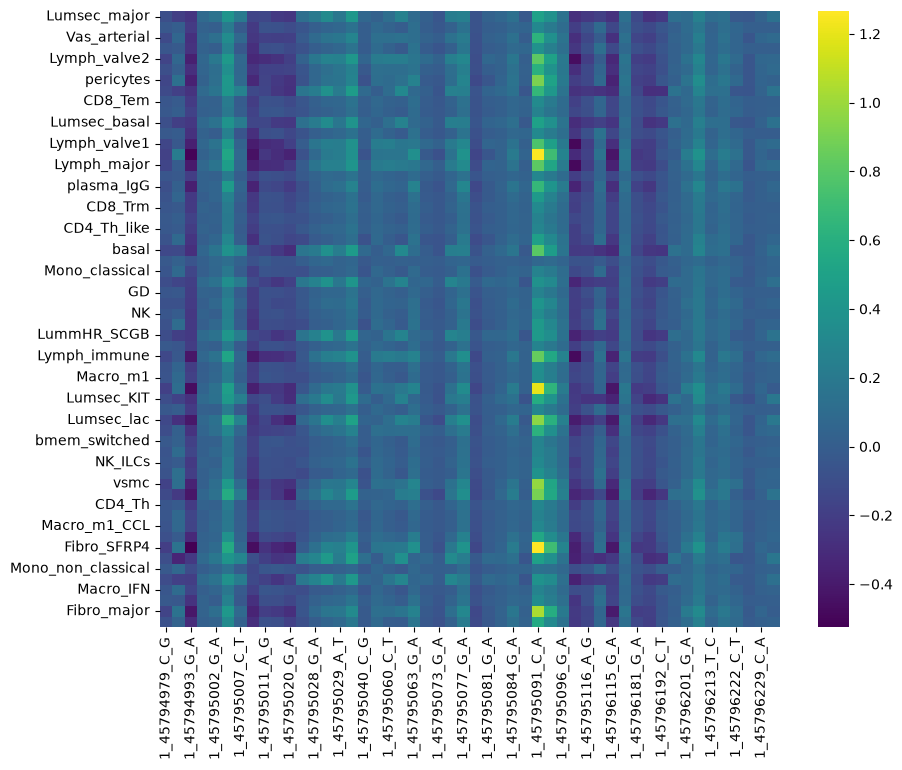

In [64]:
X = adata.X.toarray() if not isinstance(adata.X, np.ndarray) else adata.X
df = pd.DataFrame(X, index=adata.obs_names, columns=adata.var_names)

df_subset = df.iloc[:, :50]


plt.figure(figsize=(10,8))
sns.heatmap(df_subset, cmap='viridis')
plt.show()


/storage/mathelierarea/processed/eirikhoy/action_var/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/storage/mathelierarea/processed/eirikhoy/action_var/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


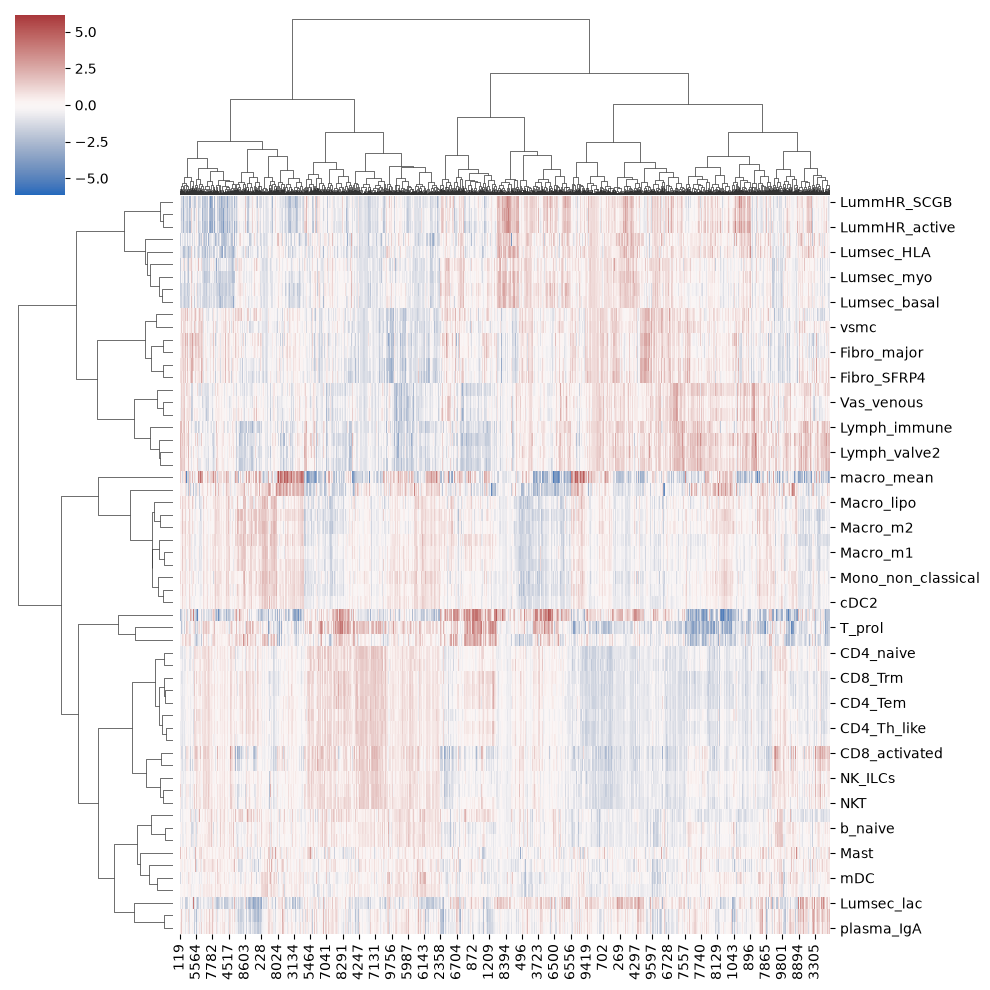

In [4]:
g = sns.clustermap(
    #df_subset,
    df,
    cmap='vlag',
    z_score=1,          # standardize per column (feature); use z_score=0 for per-row
    method='ward',       # linkage method
    metric='euclidean',
    figsize=(10, 10)
)

In [5]:
adata.var

,SNP,chrom,snp_chromStart,snp_chromEnd,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist
0,1_45794979_C_G,1,45794979,45794980,C,G,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2411
1,1_45794983_G_A,1,45794983,45794984,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2415
2,1_45794993_G_A,1,45794993,45794994,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2425
3,1_45794998_G_C,1,45794998,45794999,G,C,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2430
4,1_45795002_G_A,1,45795002,45795003,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10061,8_90996799_T_A,8,90996799,90996800,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72
10062,8_90996805_G_A,8,90996805,90996806,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66
10063,8_90996810_G_A,8,90996810,90996811,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61
10064,8_90996815_C_T,8,90996815,90996816,C,T,8,90996871,90996872,-,NBN,ENSG00000104320,True,56


In [6]:
adata.var['gene_name'].astype(str)


0        HPDL
1        HPDL
2        HPDL
3        HPDL
4        HPDL
         ... 
10061     NBN
10062     NBN
10063     NBN
10064     NBN
10065     NBN
Name: gene_name, Length: 10066, dtype: str

/storage/scratch/tmp/ipykernel_933903/2788312599.py:4: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)


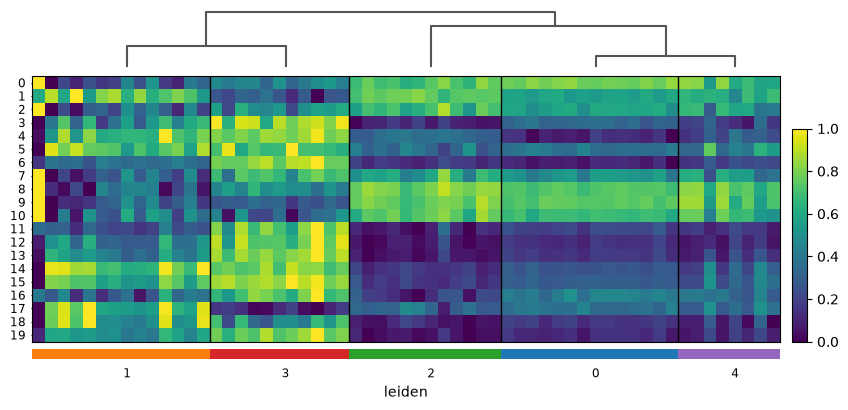

In [7]:
# Cluster
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.leiden(adata)
sc.tl.dendrogram(adata, groupby='leiden')

sc.pl.heatmap(
    adata,
    var_names=adata.var_names[:20],
    groupby='leiden',
    dendrogram=True,
    cmap='viridis',
    standard_scale='var',
    swap_axes=True
)

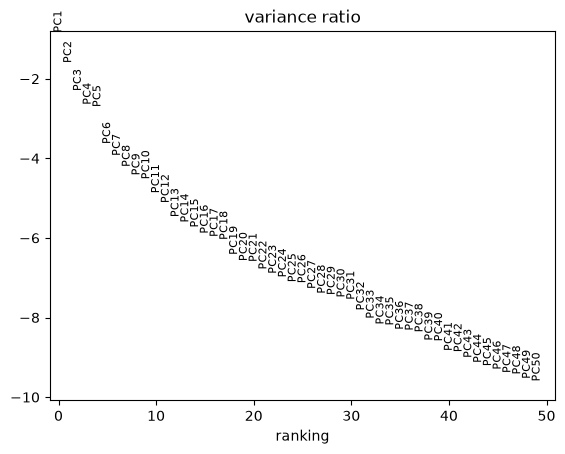

In [8]:
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

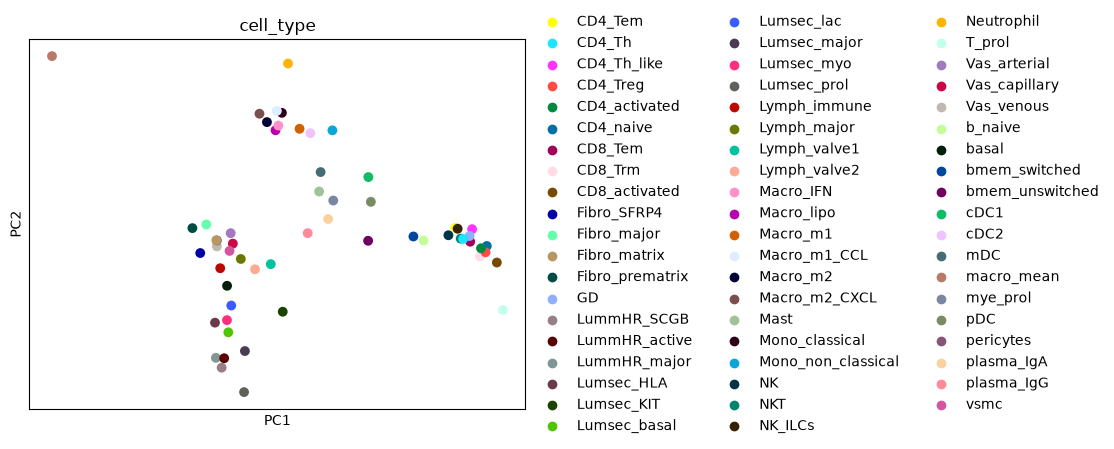

In [9]:
sc.pl.pca(
    adata,
    size=200,
color=['cell_type']
)

In [10]:
adata.var_names

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
       ...
       '10056', '10057', '10058', '10059', '10060', '10061', '10062', '10063',
       '10064', '10065'],
      dtype='str', length=10066)

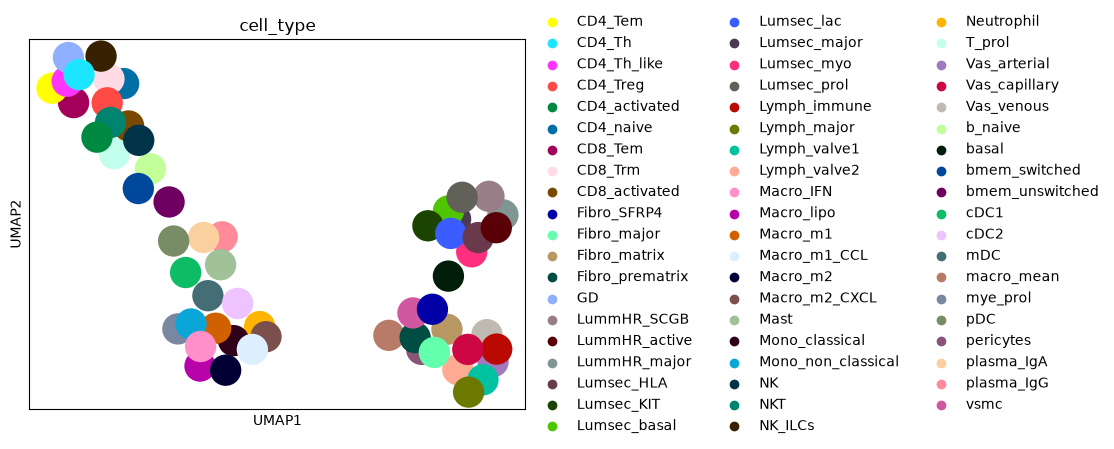

In [11]:
sc.pp.neighbors(adata)
sc.tl.umap(adata)

sc.pl.umap(
    adata,
    color='cell_type',#size=200
)

In [12]:
sc.tl.leiden(adata, flavor='igraph', n_iterations=2)

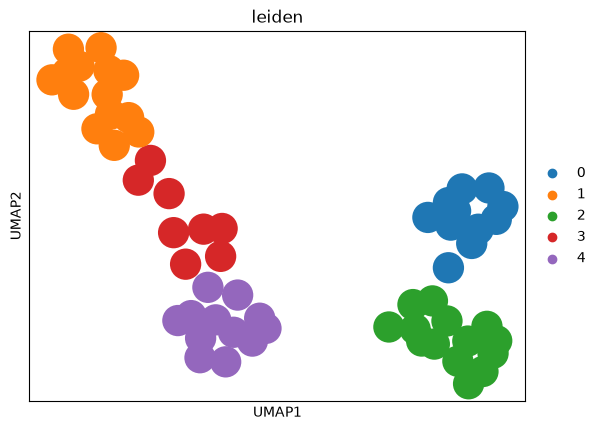

In [13]:
sc.pl.umap(adata, color=["leiden"])

In [14]:
# TODO, compare leiden cluster to cell types

adata.obs

,cell_type,leiden
Lumsec_major,Lumsec_major,0
CD4_naive,CD4_naive,1
Vas_arterial,Vas_arterial,2
T_prol,T_prol,1
Lymph_valve2,Lymph_valve2,2
Vas_venous,Vas_venous,2
pericytes,pericytes,2
Lumsec_myo,Lumsec_myo,0
CD8_Tem,CD8_Tem,1
macro_mean,macro_mean,2


In [15]:
ct = pd.crosstab(adata.obs['cell_type'], adata.obs['leiden'])
print(ct)

leiden              0  1  2  3  4
cell_type                        
CD4_Tem             0  1  0  0  0
CD4_Th              0  1  0  0  0
CD4_Th_like         0  1  0  0  0
CD4_Treg            0  1  0  0  0
CD4_activated       0  1  0  0  0
CD4_naive           0  1  0  0  0
CD8_Tem             0  1  0  0  0
CD8_Trm             0  1  0  0  0
CD8_activated       0  1  0  0  0
Fibro_SFRP4         0  0  1  0  0
Fibro_major         0  0  1  0  0
Fibro_matrix        0  0  1  0  0
Fibro_prematrix     0  0  1  0  0
GD                  0  1  0  0  0
LummHR_SCGB         1  0  0  0  0
LummHR_active       1  0  0  0  0
LummHR_major        1  0  0  0  0
Lumsec_HLA          1  0  0  0  0
Lumsec_KIT          1  0  0  0  0
Lumsec_basal        1  0  0  0  0
Lumsec_lac          1  0  0  0  0
Lumsec_major        1  0  0  0  0
Lumsec_myo          1  0  0  0  0
Lumsec_prol         1  0  0  0  0
Lymph_immune        0  0  1  0  0
Lymph_major         0  0  1  0  0
Lymph_valve1        0  0  1  0  0
Lymph_valve2  

In [ ]:
import pandas as pd
import numpy as np
import anndata as ad
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------
# Load 
# ------------------------------------------------------------------------
meta = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv")
scores = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv")

# ------------------------------------------------------------------------
# Clean metadata
# ------------------------------------------------------------------------
meta = meta.drop_duplicates()

snp_gene_map = meta.copy()
meta_resolved = meta.sort_values(['SNP', 'dist']).drop_duplicates('SNP', keep='first')
meta_resolved = meta_resolved.loc[scores.index]

scores = scores.set_index('SNP')
meta_resolved = meta_resolved.set_index('SNP')

assert set(scores.index) == set(meta_resolved.index)

scores = scores.drop(columns='macro_mean')

var = pd.DataFrame(index=scores.columns)
var['cell_type'] = var.index

# ------------------------------------------------------------------------
# Generate anndata object
# ------------------------------------------------------------------------
adata = ad.AnnData(
    X=scores.values.astype(np.float32),
    obs=meta_resolved,
    var=var
)

# stash the full (unresolved) SNP-gene mapping for the one/few multi-gene SNPs
adata.uns['snp_gene_map_full'] = snp_gene_map.reset_index(drop=True)
adata

AnnData object with n_obs × n_vars = 10066 × 58
    obs: 'chrom', 'snp_chromStart', 'snp_chromEnd', 'ref', 'alt', 'chrom_gene', 'tss', 'tss_chromEnd', 'strand', 'gene_name', 'gene_id', 'cage_used', 'dist'
    var: 'cell_type'
    uns: 'snp_gene_map_full'
    layers: None (.X)

In [38]:
adata.uns['snp_gene_map_full']

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2411
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2415
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2425
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2430
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10062,8,90996799,90996800,8_90996799_T_A,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72
10063,8,90996805,90996806,8_90996805_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66
10064,8,90996810,90996811,8_90996810_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61
10065,8,90996815,90996816,8_90996815_C_T,C,T,8,90996871,90996872,-,NBN,ENSG00000104320,True,56


In [17]:
adata.obs

,chrom,snp_chromStart,snp_chromEnd,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist
SNP,,,,,,,,,,,,,
10_89624151_C_T,10,89624151,89624152,C,T,10,89623389,89623390,+,PTEN,ENSG00000171862,True,762
10_89624161_A_C,10,89624161,89624162,A,C,10,89623389,89623390,+,PTEN,ENSG00000171862,True,772
10_89624199_C_T,10,89624199,89624200,C,T,10,89623389,89623390,+,PTEN,ENSG00000171862,True,810
10_89624200_T_C,10,89624200,89624201,T,C,10,89623389,89623390,+,PTEN,ENSG00000171862,True,811
10_89624213_A_C,10,89624213,89624214,A,C,10,89623389,89623390,+,PTEN,ENSG00000171862,True,824
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8_90996799_T_A,8,90996799,90996800,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72
8_90996805_G_A,8,90996805,90996806,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66
8_90996810_G_A,8,90996810,90996811,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61


/storage/scratch/tmp/ipykernel_933903/4175353072.py:5: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)


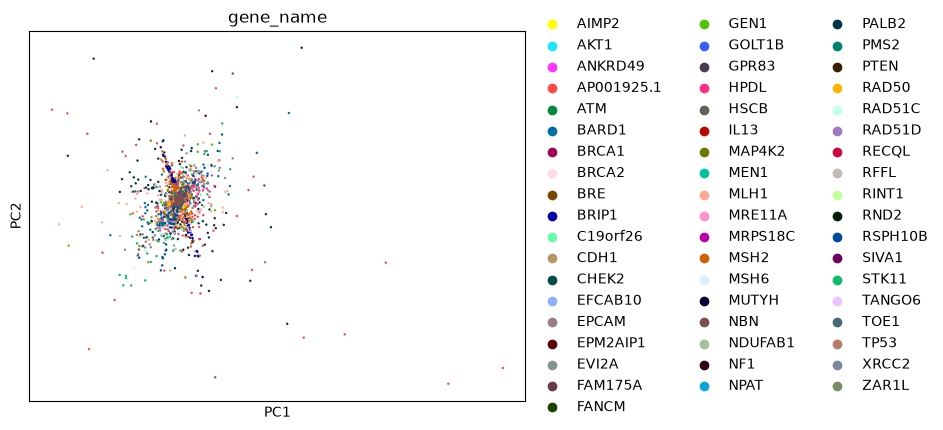

In [18]:
import scanpy as sc

sc.pp.pca(adata, n_comps=20)
sc.pp.neighbors(adata)
sc.tl.leiden(adata)
sc.pl.pca(adata, color='gene_name')

In [19]:

adata_ct = adata.T

X = adata_ct.X

cell_types = adata_ct.obs_names.to_numpy()
snp_ids = adata_ct.var_names.to_numpy()

gene_names = adata_ct.var['gene_name'].to_numpy()


pca = PCA(n_components=2)
scores = pca.fit_transform(X - X.mean(axis=0))
loadings = pca.components_.T

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Scores shape:", scores.shape, "Loadings shape:", loadings.shape)




Explained variance ratio: [0.44414714 0.2080425 ]
Scores shape: (58, 2) Loadings shape: (10066, 2)


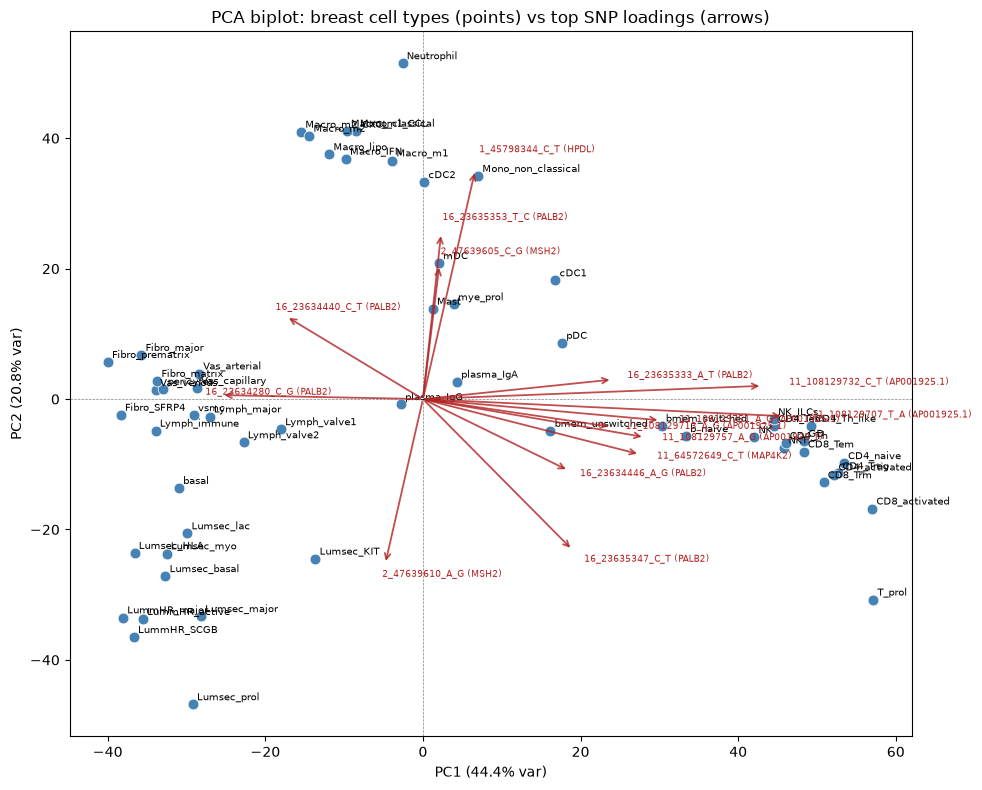

In [20]:
loading_mag = np.linalg.norm(loadings, axis=1)
top_n = 15
top_idx = np.argsort(loading_mag)[-top_n:]

# Scale factor so arrows are visible relative to the score spread
scale = (np.abs(scores).max() / np.abs(loadings[top_idx]).max()) * 0.8


fig, ax = plt.subplots(figsize=(10, 8))

# Cell type points
ax.scatter(scores[:, 0], scores[:, 1], c='steelblue', s=60, zorder=3, edgecolor='white', linewidth=0.5)
for i, ct in enumerate(cell_types):
    ax.annotate(ct, (scores[i, 0], scores[i, 1]), fontsize=7, xytext=(3, 3),
                textcoords='offset points', zorder=4)

# SNP arrows
for i in top_idx:
    x, y = loadings[i, 0] * scale, loadings[i, 1] * scale
    ax.annotate('', xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='firebrick', lw=1.3, alpha=0.8),
                zorder=5)
    label = f"{snp_ids[i]} ({gene_names[i]})"
    ax.text(x * 1.08, y * 1.08, label, fontsize=6.5, color='firebrick', zorder=6)
 
ax.axhline(0, color='grey', lw=0.5, linestyle='--')
ax.axvline(0, color='grey', lw=0.5, linestyle='--')
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title("PCA biplot: breast cell types (points) vs top SNP loadings (arrows)")
plt.tight_layout()


In [7]:
adata

AnnData object with n_obs × n_vars = 10066 × 58
    obs: 'chrom', 'snp_chromStart', 'snp_chromEnd', 'ref', 'alt', 'chrom_gene', 'tss', 'tss_chromEnd', 'strand', 'gene_name', 'gene_id', 'cage_used', 'dist', 'leiden'
    var: 'cell_type'
    uns: 'snp_gene_map_full', 'pca', 'neighbors', 'leiden', 'gene_name_colors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)

In [1]:
import pandas as pd
import seaborn as sns

In [2]:
#TODO

# Annotate the SNP, or add another column, with which gene it belongs to
# Its in the Seqweaver_bridges34_genes_input.RUNFILE.csv

In [3]:
df = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv", index_col='SNP').drop("macro_mean", axis=1)
df

,Lumsec_major,CD4_naive,Vas_arterial,T_prol,Lymph_valve2,Vas_venous,pericytes,Lumsec_myo,CD8_Tem,b_naive,...,Macro_m1_CCL,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC
SNP,,,,,,,,,,,,,,,,,,,,,
1_45794979_C_G,-0.098642,-0.037530,-0.120704,-0.046177,-0.168627,-0.097775,-0.152277,-0.121232,-0.044770,-0.035904,...,-0.058157,-0.086031,-0.202274,-0.101641,-0.034030,-0.114761,-0.046459,-0.035442,-0.163672,-0.082305
1_45794983_G_A,-0.194202,0.000243,0.060638,-0.025970,0.062815,0.007582,0.126519,-0.184144,-0.017531,0.003549,...,0.069310,-0.019523,0.158286,-0.343143,0.071504,-0.189323,0.095811,-0.039422,0.146556,0.040003
1_45794993_G_A,-0.246038,-0.215814,-0.280539,-0.263582,-0.366701,-0.284952,-0.361204,-0.264380,-0.211859,-0.171079,...,-0.162856,-0.321782,-0.525595,-0.224855,-0.117842,-0.203701,-0.158149,-0.265682,-0.417115,-0.308078
1_45794998_G_C,0.085459,0.030993,0.058055,0.033443,0.065792,0.050949,0.027174,0.084003,0.030082,0.019765,...,0.009364,0.034013,0.037675,0.088051,0.004546,0.093291,0.009438,0.037924,0.036089,0.015332
1_45795002_G_A,0.156451,0.007813,0.120878,0.005290,0.188081,0.116439,0.121432,0.160059,0.020633,0.029458,...,0.066755,0.052820,0.095924,0.184090,0.052263,0.155310,0.050283,-0.003054,0.116481,0.039094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8_90996799_T_A,0.284476,0.224080,-0.263773,0.068867,-0.479779,-0.189315,-0.574833,-0.041605,0.092080,0.347767,...,-0.481346,0.174968,-0.753059,0.088084,-0.440934,0.022356,-0.395922,0.338504,-0.713791,-0.032397
8_90996805_G_A,-0.076384,0.051730,-0.481214,-0.082722,-0.312230,-0.388185,-0.277128,-0.145873,-0.008884,-0.358352,...,-0.445344,-0.257611,-0.200781,-0.274405,-0.373441,-0.157192,-0.629108,0.134022,-0.226881,-0.418884
8_90996810_G_A,0.848272,0.764258,0.287601,0.643362,0.251251,0.362762,0.128682,0.629247,0.512433,0.763829,...,-0.188455,0.278797,0.250662,0.539204,-0.102425,0.595538,-0.173763,0.941237,0.069983,0.282454


In [4]:
df_filtered = df[(df.abs() > 5).any(axis=1)]
df_filtered

,Lumsec_major,CD4_naive,Vas_arterial,T_prol,Lymph_valve2,Vas_venous,pericytes,Lumsec_myo,CD8_Tem,b_naive,...,Macro_m1_CCL,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC
SNP,,,,,,,,,,,,,,,,,,,,,
1_45800062_C_T,-4.046251,0.832841,2.717962,2.096525,3.282668,3.347677,-0.871141,-3.384650,0.243556,0.878050,...,3.365031,-0.503543,-1.527568,-2.855636,3.792672,-1.770642,3.405108,1.141663,-0.936324,3.025449
1_45800154_C_G,-2.937479,5.686300,1.466255,7.628654,2.204314,1.524374,-1.507601,-3.053122,4.277064,2.576430,...,1.845323,0.755468,-2.874401,-2.723168,3.338236,-2.855069,2.116407,6.130876,-1.735344,3.221803
1_45800178_G_A,-0.258585,-0.231883,3.903241,0.093547,3.451556,4.159781,1.005605,0.190586,-0.182963,0.765990,...,3.694377,0.514420,0.030965,1.363988,3.655623,0.029311,3.779967,-0.402673,0.528756,2.723759
1_45805566_G_C,-3.841604,-1.576696,-1.976987,-3.040386,-1.743357,-3.003495,-1.542506,-2.976409,-1.887441,-1.771234,...,-1.984390,-2.141738,-1.242069,-3.278260,-2.155736,-3.067648,-2.159203,-1.574598,-1.386133,-2.032047
1_45805624_G_A,7.555773,3.560311,4.349861,2.954771,5.517923,5.569538,3.998787,6.866773,3.138270,3.960304,...,3.028439,4.708424,5.381764,8.015066,3.160007,6.411478,3.309010,3.640033,4.227689,4.313324
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7_6048664_G_C,-3.854455,-2.248674,-2.619266,-4.864861,-2.968393,-2.781076,-2.587568,-3.334082,-3.007444,-2.551990,...,-2.245535,-3.004622,-2.230204,-3.266782,-2.156479,-4.711429,-2.395373,-2.210790,-2.411218,-1.889903
7_6048669_G_A,-5.237798,-3.035845,-3.717007,-6.573653,-4.228094,-3.894938,-3.885539,-4.512817,-3.694866,-3.592379,...,-2.886019,-4.150117,-3.319888,-4.825149,-2.859024,-5.641647,-3.128224,-2.949529,-3.516625,-2.504679
7_105172775_G_A,-2.406260,-3.986986,-2.735592,-5.427804,-2.776761,-2.751608,-2.254498,-2.460981,-4.126721,-4.023081,...,-2.596220,-3.026631,-2.314967,-2.105788,-3.095764,-2.762963,-2.768378,-4.911872,-2.138836,-3.990853


<Axes: ylabel='Count'>

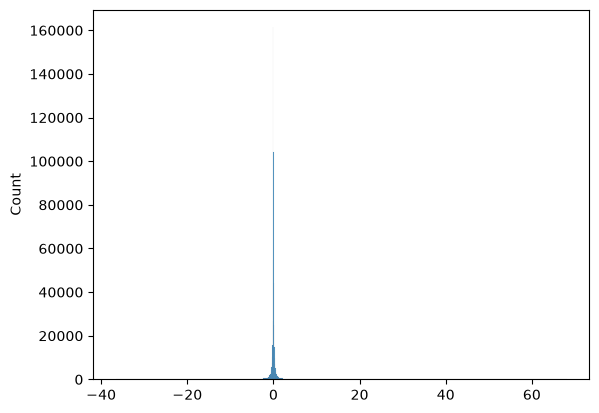

In [5]:
all_values = df.stack()

sns.histplot(
    data=all_values
)

<Axes: ylabel='Count'>

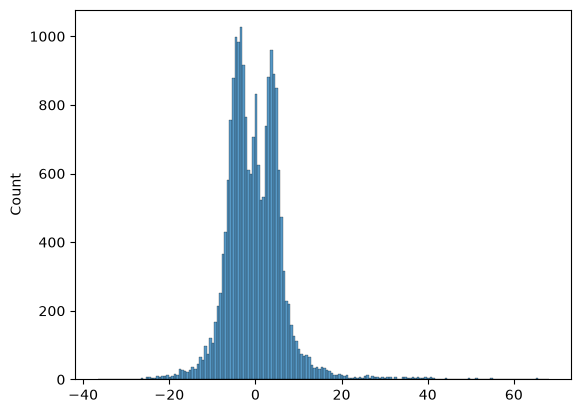

In [6]:
all_values = df_filtered.stack()

sns.histplot(
    data=all_values
)

/storage/mathelierarea/processed/eirikhoy/action_var/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/storage/mathelierarea/processed/eirikhoy/action_var/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


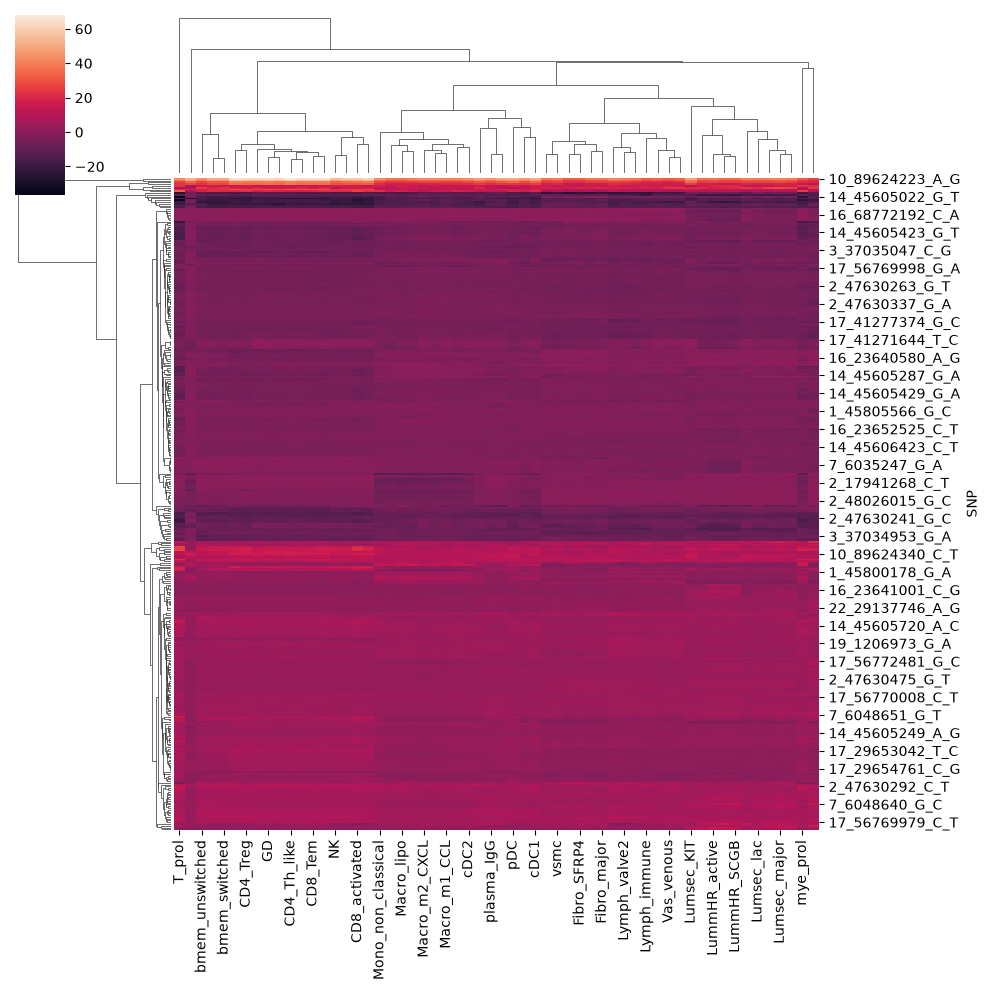

In [7]:
sns.clustermap(df_filtered)

<Axes: ylabel='Count'>

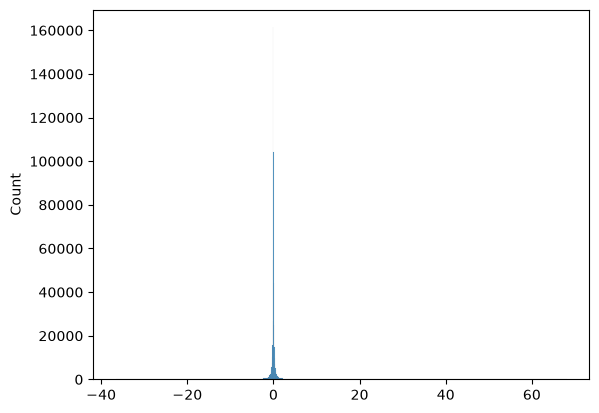

In [43]:
X = df.copy()

sns.histplot(X.stack())

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd


#X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components = 10, svd_solver='auto')
X_pca = pca.fit_transform(X)

# variance explained
pca.explained_variance_ratio_


array([0.89986954, 0.04055677, 0.02008231, 0.01265957, 0.00914017,
       0.0036797 , 0.0025924 , 0.00196823, 0.00159256, 0.00145217])

---

PCA using ISLRp lab method
---


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import \
    (KMeans, 
     AgglomerativeClustering)
from scipy.cluster.hierarchy import \
    (dendrogram,
     cut_tree)

scaler = StandardScaler(with_std=True,
                        with_mean=True)
df_scaled = scaler.fit_transform(df)
pca = PCA()
pca.fit(df_scaled)
scores = pca.transform(df_scaled)
scores

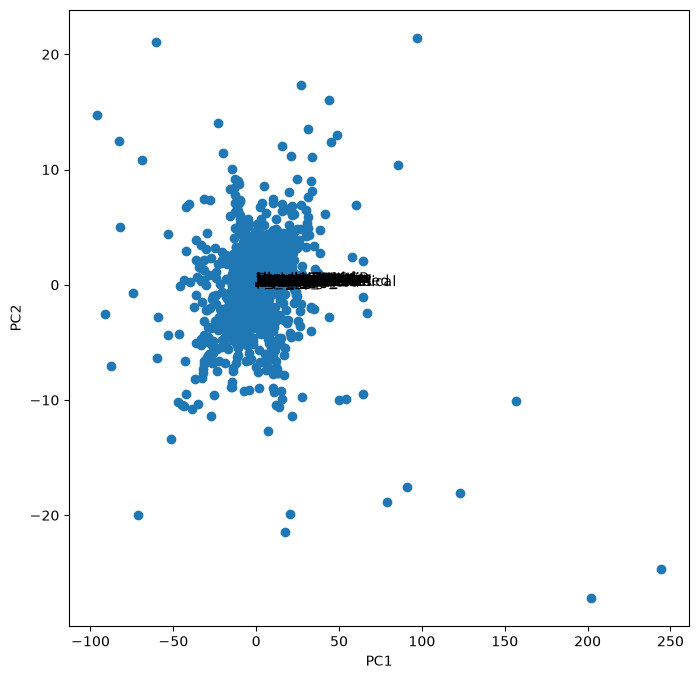

In [21]:
i, j = 0, 1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, pca.components_[i,k], pca.components_[j,k])
    ax.text(pca.components_[i,k],
            pca.components_[j, k],
            df.columns[k])

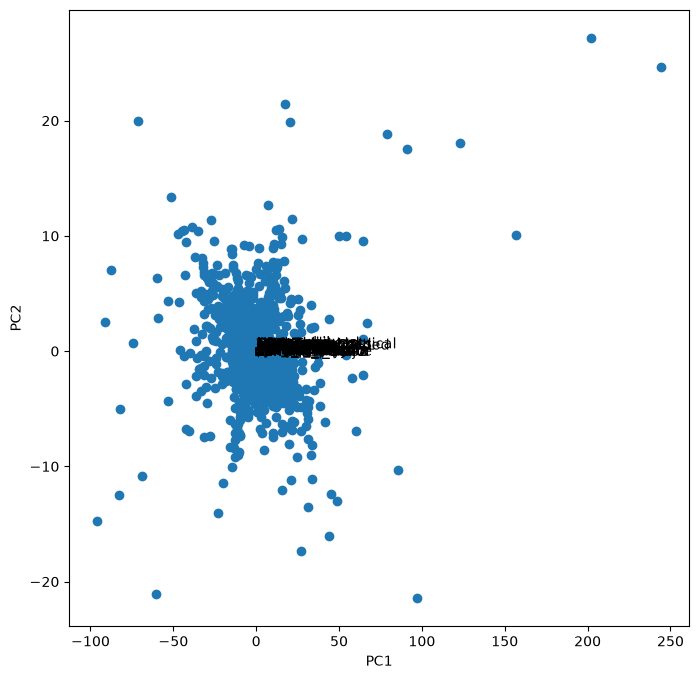

In [22]:
scale_arrow = s_ = 2
scores[:, 1] *= -1
pca.components_[1] *= -1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, s_*pca.components_[i, k], s_*pca.components_[j,k])
    ax.text(s_*pca.components_[i,k],
            s_*pca.components_[j,k],
            df.columns[k])

In [26]:
df_T = df.T
df_T

SNP,1_45794979_C_G,1_45794983_G_A,1_45794993_G_A,1_45794998_G_C,1_45795002_G_A,1_45795006_G_A,1_45795007_C_T,1_45795010_C_T,1_45795011_A_G,1_45795013_T_C,...,8_90996779_A_C,8_90996788_A_G,8_90996791_G_A,8_90996791_G_T,8_90996794_C_T,8_90996799_T_A,8_90996805_G_A,8_90996810_G_A,8_90996815_C_T,8_90996827_G_C
Lumsec_major,-0.098642,-0.194202,-0.246038,0.085459,0.156451,0.399092,0.208638,-0.156619,-0.142100,-0.221734,...,1.085997,0.459476,-0.643215,-2.789815,-1.117645,0.284476,-0.076384,0.848272,1.762567,-1.530450
CD4_naive,-0.037530,0.000243,-0.215814,0.030993,0.007813,0.212656,-0.027812,-0.219238,-0.075324,-0.080234,...,0.352890,-0.135805,-0.507266,-2.061146,-0.356475,0.224080,0.051730,0.764258,0.889694,-1.123052
Vas_arterial,-0.120704,0.060638,-0.280539,0.058055,0.120878,0.336997,0.072693,-0.239815,-0.188873,-0.189830,...,0.695945,-0.132026,-0.675130,-2.062694,-0.870792,-0.263773,-0.481214,0.287601,1.282415,-0.758527
T_prol,-0.046177,-0.025970,-0.263582,0.033443,0.005290,0.263381,-0.036592,-0.281834,-0.097217,-0.087863,...,0.537355,-0.072996,-0.597021,-2.531419,-0.688105,0.068867,-0.082722,0.643362,0.817321,-1.271223
Lymph_valve2,-0.168627,0.062815,-0.366701,0.065792,0.188081,0.434461,0.073516,-0.324874,-0.299276,-0.268918,...,0.922453,0.167614,-0.766279,-2.281712,-1.065464,-0.479779,-0.312230,0.251251,0.927034,-0.787272
Vas_venous,-0.097775,0.007582,-0.284952,0.050949,0.116439,0.356132,0.066109,-0.254213,-0.174623,-0.174977,...,0.760837,0.120445,-0.705341,-2.129710,-0.882685,-0.189315,-0.388185,0.362762,1.635840,-1.070555
pericytes,-0.152277,0.126519,-0.361204,0.027174,0.121432,0.423105,0.076832,-0.328527,-0.165769,-0.227193,...,0.923145,0.045427,-0.571420,-1.774601,-0.818931,-0.574833,-0.277128,0.128682,0.865518,-0.391166
Lumsec_myo,-0.121232,-0.184144,-0.264380,0.084003,0.160059,0.412619,0.263781,-0.133188,-0.155985,-0.239479,...,1.134665,0.357395,-0.528544,-2.435000,-1.096452,-0.041605,-0.145873,0.629247,1.636323,-1.308810
CD8_Tem,-0.044770,-0.017531,-0.211859,0.030082,0.020633,0.211852,-0.010174,-0.207812,-0.074709,-0.082072,...,0.383693,-0.165510,-0.483006,-1.933230,-0.328014,0.092080,-0.008884,0.512433,0.792097,-0.879414
b_naive,-0.035904,0.003549,-0.171079,0.019765,0.029458,0.193228,0.001407,-0.170344,-0.051239,-0.047647,...,0.468378,-0.391514,-0.886670,-3.338156,-0.679593,0.347767,-0.358352,0.763829,1.210527,-1.396000


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import \
    (KMeans, 
     AgglomerativeClustering)
from scipy.cluster.hierarchy import \
    (dendrogram,
     cut_tree)





scaler = StandardScaler(with_std=True,
                        with_mean=True)
df_scaled = scaler.fit_transform(df_T)
pca = PCA()
pca.fit(df_scaled)
scores = pca.transform(df_scaled)
scores

array([[-5.42579379e+01,  6.26757289e+01, -2.06512129e+01, ...,
        -7.30188557e-01,  1.26096998e-01,  5.06913016e-14],
       [ 6.82024067e+01,  1.91348206e+01,  3.25139593e+01, ...,
         1.07087639e+00, -2.01908033e-01,  9.91664144e-14],
       [-6.61023824e+01, -3.92064318e+01,  2.24739824e+01, ...,
         7.94671237e-02, -2.62788514e-01, -2.97044579e-14],
       ...,
       [ 5.91590082e+01,  1.21229247e+01,  6.36100634e+01, ...,
         2.51029540e-01, -4.80069484e-03,  1.73704013e-13],
       [-3.73655157e+01, -1.38467088e+01, -2.99686672e+01, ...,
         2.78430089e-01,  6.00158072e-02, -2.17785063e-14],
       [ 3.11863035e+01, -7.78617888e+00,  1.79549503e+01, ...,
        -8.29267723e-02,  7.48822878e-03, -2.04184831e-14]],
      shape=(58, 58))

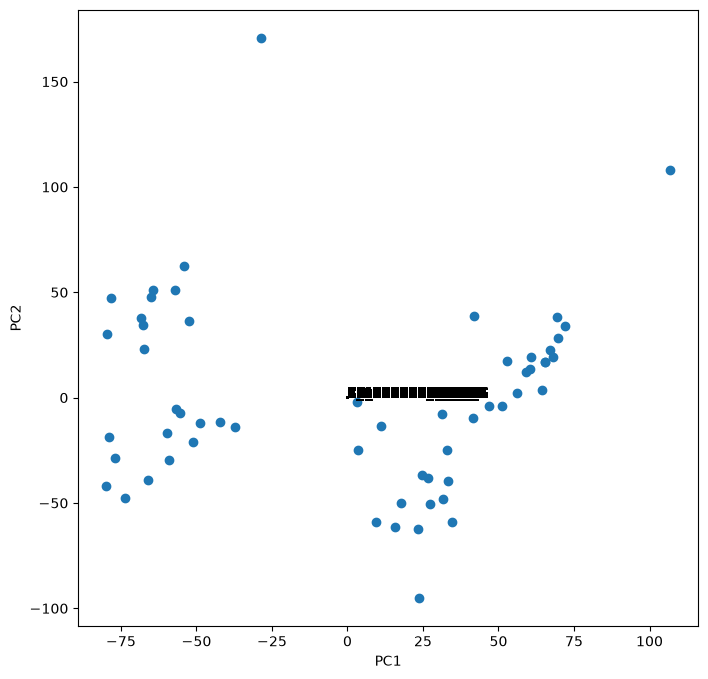

In [28]:
i, j = 0, 1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, pca.components_[i,k], pca.components_[j,k])
    ax.text(pca.components_[i,k],
            pca.components_[j, k],
            df_T.columns[k])

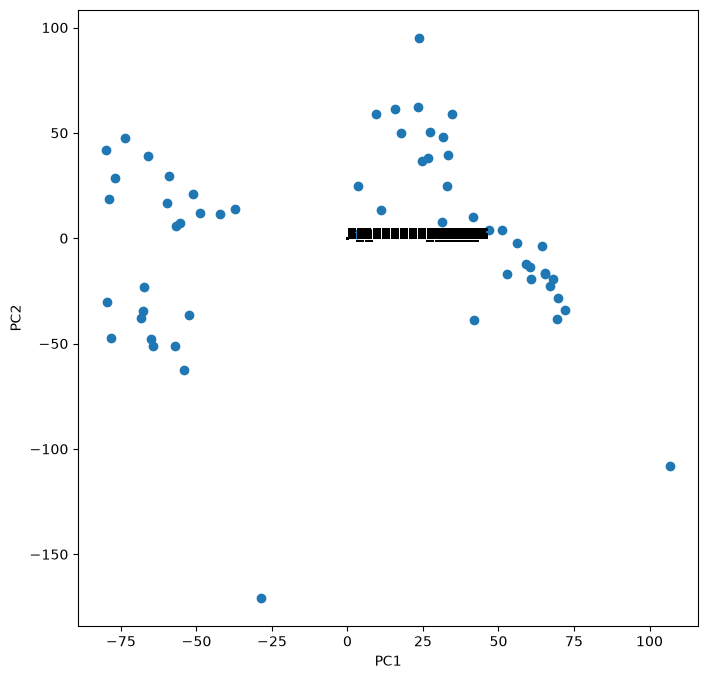

In [29]:
scale_arrow = s_ = 2
scores[:, 1] *= -1
pca.components_[1] *= -1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, s_*pca.components_[i, k], s_*pca.components_[j,k])
    ax.text(s_*pca.components_[i,k],
            s_*pca.components_[j,k],
            df_T.columns[k])